# Практическая работа: свёрточные нейронные сети

## Подготовка

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np
import random

torch.manual_seed(42)
random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


## 1. Усложните модель LeNet или напишите свою модель с нуля

In [ ]:
class CNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CNN(num_classes=10).to(device)
print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU()
    (7): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU()
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU()
    (12): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=128, out_features=10, bias=True)
  )
)


## 2. Добавьте расчёт train/val метрик

In [ ]:
def train_model(model, train_loader, val_loader, epochs=3, lr=0.001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        history["train_loss"].append(train_loss / train_total)
        history["train_acc"].append(train_correct / train_total)
        history["val_loss"].append(val_loss / val_total)
        history["val_acc"].append(val_correct / val_total)

        print(
            f"Эпоха {epoch + 1}/{epochs}: "
            f"train loss={history['train_loss'][-1]:.4f}, "
            f"train acc={history['train_acc'][-1]:.4f}, "
            f"val loss={history['val_loss'][-1]:.4f}, "
            f"val acc={history['val_acc'][-1]:.4f}"
        )

    return history

## 3. Обучите модель на наборе данных CIFAR-10

In [ ]:
cifar_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])

cifar_full = datasets.CIFAR10(
    root="data", train=True, download=True, transform=cifar_transform
)
cifar_test = datasets.CIFAR10(
    root="data", train=False, download=True, transform=cifar_transform
)

train_size = int(0.9 * len(cifar_full))
val_size = len(cifar_full) - train_size
cifar_train, cifar_val = random_split(
    cifar_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(cifar_train, batch_size=128, shuffle=True, num_workers=0)
val_loader = DataLoader(cifar_val, batch_size=128, shuffle=False, num_workers=0)
test_loader = DataLoader(cifar_test, batch_size=128, shuffle=False, num_workers=0)

model = CNN(num_classes=10).to(device)
cifar_history = train_model(model, train_loader, val_loader, epochs=3)

Эпоха 1/3: train loss=1.7874, train acc=0.3290, val loss=1.5575, val acc=0.4306
Эпоха 2/3: train loss=1.4504, train acc=0.4678, val loss=1.3431, val acc=0.5116
Эпоха 3/3: train loss=1.2264, train acc=0.5553, val loss=1.1779, val acc=0.5776


## 4. Возьмите более сложный датасет, связанный с транспортом

В качестве более сложного набора данных использую **GTSRB** — датасет изображений дорожных знаков. Он связан с транспортом и содержит больше классов, чем CIFAR-10.

## 5. Попробуйте обучить модель на нём

In [ ]:
gtsrb_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.3403, 0.3121, 0.3214),
                         (0.2724, 0.2608, 0.2669))
])

gtsrb_full = datasets.GTSRB(
    root="data", split="train", download=True, transform=gtsrb_transform
)
gtsrb_test = datasets.GTSRB(
    root="data", split="test", download=True, transform=gtsrb_transform
)

train_size = int(0.9 * len(gtsrb_full))
val_size = len(gtsrb_full) - train_size
gtsrb_train, gtsrb_val = random_split(
    gtsrb_full, [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(gtsrb_train, batch_size=128, shuffle=True, num_workers=0)
val_loader = DataLoader(gtsrb_val, batch_size=128, shuffle=False, num_workers=0)
gtsrb_test_loader = DataLoader(gtsrb_test, batch_size=128, shuffle=False, num_workers=0)

gtsrb_model = CNN(num_classes=43).to(device)
gtsrb_history = train_model(gtsrb_model, train_loader, val_loader, epochs=3)

100%|██████████| 187M/187M [00:04<00:00, 42.7MB/s]
100%|██████████| 89.0M/89.0M [00:02<00:00, 34.7MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 1.42MB/s]


Эпоха 1/3: train loss=3.3250, train acc=0.0961, val loss=3.0574, val acc=0.1321
Эпоха 2/3: train loss=2.7936, train acc=0.1906, val loss=2.4686, val acc=0.2350
Эпоха 3/3: train loss=1.9722, train acc=0.3733, val loss=1.7224, val acc=0.4276


## 6. Посчитайте количество параметров модели

In [ ]:
total_params = sum(parameter.numel() for parameter in gtsrb_model.parameters())
trainable_params = sum(
    parameter.numel() for parameter in gtsrb_model.parameters()
    if parameter.requires_grad
)
print("Всего параметров:", total_params)
print("Обучаемых параметров:", trainable_params)

Всего параметров: 144971
Обучаемых параметров: 144971


## 7. Визуализируйте loss и метрики

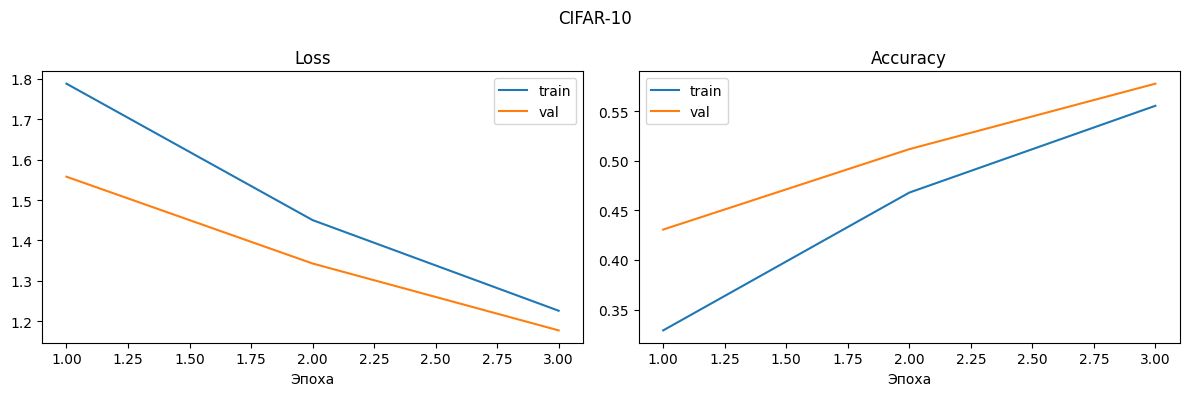

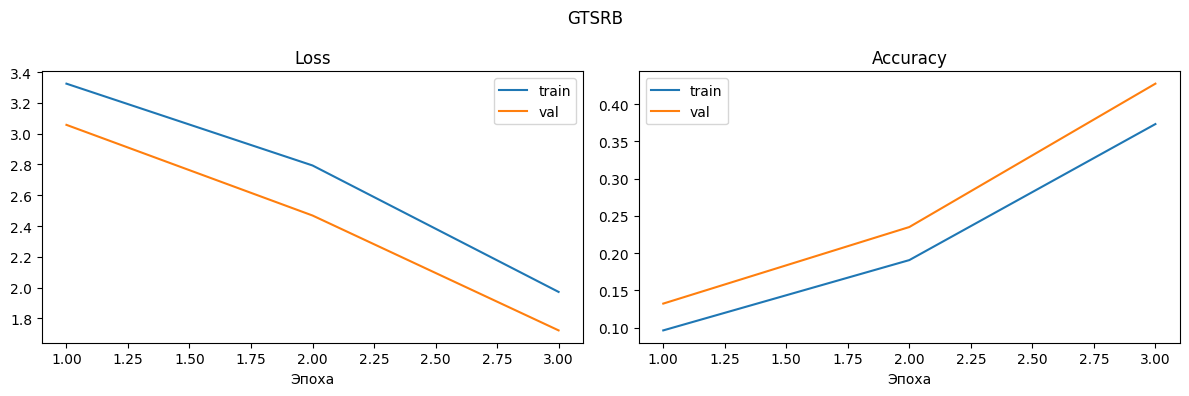

In [ ]:
def plot_history(history, title):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(epochs, history["train_loss"], label="train")
    ax[0].plot(epochs, history["val_loss"], label="val")
    ax[0].set_title("Loss")
    ax[0].set_xlabel("Эпоха")
    ax[0].legend()

    ax[1].plot(epochs, history["train_acc"], label="train")
    ax[1].plot(epochs, history["val_acc"], label="val")
    ax[1].set_title("Accuracy")
    ax[1].set_xlabel("Эпоха")
    ax[1].legend()

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(cifar_history, "CIFAR-10")
plot_history(gtsrb_history, "GTSRB")

## 8. Визуализируйте карты признаков последнего свёрточного слоя и попробуйте их интерпретировать

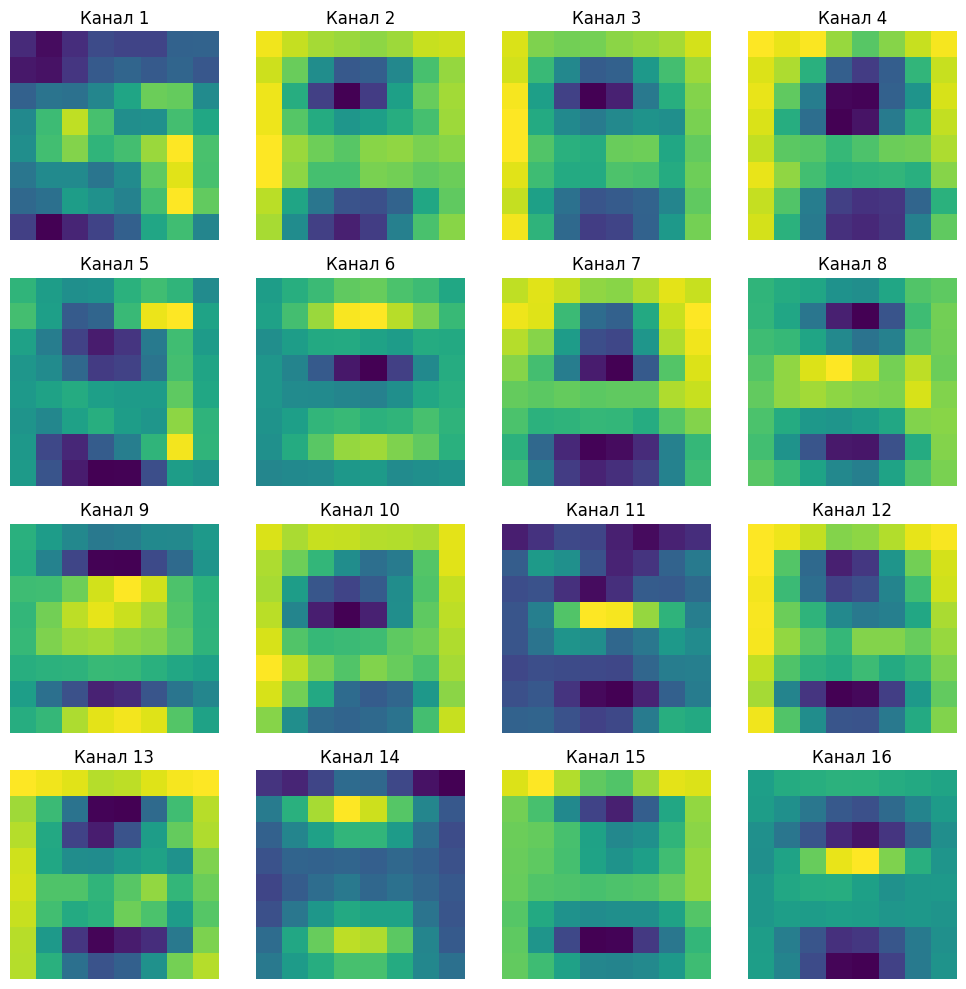

Истинный класс: 16
Предсказанный класс: 15


In [ ]:
gtsrb_model.eval()
feature_maps = {}

def save_feature_maps(module, inputs, output):
    feature_maps["maps"] = output.detach().cpu()

hook = gtsrb_model.features[10].register_forward_hook(save_feature_maps)

images, labels = next(iter(gtsrb_test_loader))
sample = images[0:1].to(device)

with torch.no_grad():
    prediction = gtsrb_model(sample).argmax(1).item()

hook.remove()

maps = feature_maps["maps"][0]
count = min(16, maps.shape[0])
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < count:
        ax.imshow(maps[i], cmap="viridis")
        ax.set_title(f"Канал {i + 1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

print("Истинный класс:", labels[0].item())
print("Предсказанный класс:", prediction)

**Интерпретация:** карты признаков показывают, на какие области изображения реагируют разные каналы последнего свёрточного слоя. Светлые участки соответствуют более сильным активациям. Разные каналы могут выделять контуры, цвета и отдельные части дорожного знака; без дополнительного анализа нельзя точно назначить каждому каналу конкретный признак.

In [ ]:

def evaluate_model(model, test_loader):
    model.eval()
    device = next(model.parameters()).device
    criterion = nn.CrossEntropyLoss()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    print(f"Test Loss: {total_loss / total:.4f}")
    print(f"Test Accuracy: {100 * correct / total:.2f}%")


## 9. Проверьте финальное качество модели на test-выборке

In [ ]:
print("CIFAR-10:")
evaluate_model(model, test_loader)

print("GTSRB:")
evaluate_model(gtsrb_model, gtsrb_test_loader)

CIFAR-10:
Test Loss: 1.1625
Test Accuracy: 57.96%
GTSRB:
Test Loss: 2.0373
Test Accuracy: 37.51%
